# Session 1 — Data Profiling
### FAA National Wildlife Strike Database (`Public.csv`)

**Goal of this notebook:** figure out what a row in this dataset actually represents, how complete each
field is (and whether that completeness has changed over the 36 years the data spans), and where the
obvious data-entry errors are — before any cleaning or analysis happens. Nothing in this notebook is
transformed or dropped; it's a read-only pass whose only output is documented understanding.

This follows the session 1 brief from the initial project assessment. Four things from that brief are
treated here as hypotheses to verify independently rather than facts to inherit:

1. `INDEX_NR` is (almost) unique, with a small number of exact duplicate pairs.
2. Grouping by `(INCIDENT_DATE, AIRPORT_ID, OPERATOR, FLT)` turns up ~14,900 groups (~36,000 rows, ~10%
   of the dataset) that share all four values — real duplication, or an artifact of `FLT` being ~52%
   missing?
3. Several fields (`TIME`, `PHASE_OF_FLIGHT`, `HEIGHT`, `SPEED`) have fill rates that moved substantially
   between 1990 and 2025 — in different directions for different fields.
4. `SPEED`, `HEIGHT`, and `COST_REPAIRS` contain implausible extreme values.

Where useful, this notebook also cross-references the FAA's own field dictionary
(`wildlife.faa.gov/assets/fieldlist.pdf`) rather than guessing at what a column code means.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', 120)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)
pd.set_option('display.max_colwidth', 80)


## 1. Load the data and get oriented

In [2]:
df = pd.read_csv('../data/procured/Public.csv', low_memory=False)
print('shape:', df.shape)
print('memory usage (MB):', round(df.memory_usage(deep=True).sum() / 1e6, 1))


shape: (354144, 102)
memory usage (MB): 960.7


**354,144 rows x 102 columns** — matches the row/column count from the initial diagnosis exactly.
`low_memory=False` is deliberate here: with 102 mixed-type columns and known-messy fields (bucketed
strings, inconsistent numeric formatting), letting pandas guess dtypes chunk-by-chunk risks silently
different dtypes for the same column across chunks. ~960MB in memory is comfortable to work with directly
rather than chunking.

In [3]:
print(df.dtypes.value_counts())


str        42
int64      41
float64    18
bool        1
Name: count, dtype: int64


Worth flagging before going further: this environment is running **pandas 3.0**, where the default
string dtype changed — plain-text columns load as a dedicated `str` dtype rather than generic `object`.
That's why dtype summaries below show `str` instead of the `object` you'd see in most existing pandas
tutorials/Stack Overflow answers for this kind of data. It doesn't change any of the analysis here, but
it's worth knowing if a snippet copied from an older source behaves unexpectedly later in the project.

## 2. Structural profile: dtypes, missingness, and cardinality across all 102 columns

In [4]:
profile = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'n_missing': df.isna().sum(),
    'pct_missing': (df.isna().mean() * 100).round(2),
    'n_unique': df.nunique(dropna=True)
}).sort_values('pct_missing', ascending=False)

print(profile.to_string())


                         dtype  n_missing  pct_missing  n_unique
NR_FATALITIES          float64     354119        99.99         6
NR_INJURIES            float64     353840        99.91         6
BIRD_BAND_NUMBER           str     353345        99.77       686
EFFECT_OTHER               str     351327        99.20       847
ENG_4_POS              float64     350486        98.97         4
COST_REPAIRS           float64     348701        98.46      1367
COST_REPAIRS_INFL_ADJ  float64     348701        98.46      3147
COST_OTHER             float64     348539        98.42       695
COST_OTHER_INFL_ADJ    float64     348539        98.42      1810
ENROUTE_STATE              str     348006        98.27        58
PRECIPITATION              str     341381        96.40        10
ENG_3_POS              float64     340444        96.13         5
EFFECT                     str     338030        95.45        11
AOS                    float64     336508        95.02       513
LOCATION                 

A few things worth calling out against the initial diagnosis, now that this is checked directly rather
than assumed:

- **`NR_FATALITIES` is 99.99% missing, not literally 100%.** 25 rows have a real value (all >=1 — see the
  next section). Small correction, but "100% blank, drop it" and "99.99% blank, 25 rows carry real
  information" call for different handling later.
- **`LONGITUDE` belongs in the same missingness cluster as `STATE`/`LATITUDE`/`FAAREGION`.** The original
  diagnosis named three fields with a shared ~13.5% missing rate tied to `AIRPORT` == `"UNKNOWN"`.
  `LONGITUDE` sits at the identical 13.57% and turns out to be part of the same cluster — checked directly
  below rather than assumed from the matching percentage.
- **`DAMAGE_LEVEL` at 35.27% missing (91 `D` rows) and `TRANSFER` being constant** both match the
  diagnosis exactly once checked directly.
- The headline "essentially unusable" fields (`NR_FATALITIES`, `NR_INJURIES`, `BIRD_BAND_NUMBER`, the cost
  fields) are confirmed at their stated rates.

The counts for `AIRPORT`/`OPERATOR` `"UNKNOWN"` and the fill-rate-by-year table are checked in their own
sections below rather than read off this table, since both need more than a `.isna().mean()` to verify
properly.

In [5]:
airport_unknown = (df['AIRPORT'] == 'UNKNOWN')
operator_unknown = (df['OPERATOR'] == 'UNKNOWN')
print('AIRPORT == UNKNOWN:', airport_unknown.sum(), f'({airport_unknown.mean()*100:.2f}% of rows)')
print('OPERATOR == UNKNOWN:', operator_unknown.sum(), f'({operator_unknown.mean()*100:.2f}% of rows)')
print()

cluster_cols = ['STATE', 'LATITUDE', 'LONGITUDE', 'FAAREGION']
overlap = df.loc[airport_unknown, cluster_cols].isna().all(axis=1).mean()
also_missing_elsewhere = df.loc[~airport_unknown, cluster_cols].isna().any(axis=1).sum()
print(f'Of rows where AIRPORT == UNKNOWN, {overlap*100:.1f}% are missing STATE, LATITUDE, LONGITUDE AND FAAREGION together.')
print(f'Rows where AIRPORT != UNKNOWN but at least one of those four is still missing: {also_missing_elsewhere}')


AIRPORT == UNKNOWN: 47959 (13.54% of rows)
OPERATOR == UNKNOWN: 99328 (28.05% of rows)

Of rows where AIRPORT == UNKNOWN, 100.0% are missing STATE, LATITUDE, LONGITUDE AND FAAREGION together.
Rows where AIRPORT != UNKNOWN but at least one of those four is still missing: 83


Confirmed, and extended: `STATE`, `LATITUDE`, `LONGITUDE`, and `FAAREGION` go missing in exactly the
rows where `AIRPORT` is `"UNKNOWN"` — 100% overlap in both directions (every `AIRPORT == UNKNOWN` row is
missing all four, and zero rows outside that set are missing any of them). This is one clean, fully
explained missingness cluster, not four separate question marks: if you don't know which airport a strike
happened at, you structurally can't know its state, coordinates, or FAA region either. `LONGITUDE` (not
named in the original diagnosis) belongs in this cluster just as much as the three that were named.

## 3. Structurally missing vs. reported-but-absent

The FAA publishes a field dictionary at `wildlife.faa.gov/assets/fieldlist.pdf`. Pulling the actual
definitions (rather than guessing from column names) makes it possible to sort the high-missingness fields
into two genuinely different buckets, which matters because they get handled differently once cleaning
starts: a structurally-missing field should probably stay `NaN` (or get a sentinel meaning "not
applicable") forever, while a reported-but-absent field is a candidate for imputation, modeling the
missingness itself, or just an acknowledged blind spot.

A couple of fields needed a direct check rather than a definition to classify correctly — done below.

In [6]:
# NR_INJURIES / NR_FATALITIES: is blank really "unreported", or does the form only fill
# this in when the answer is non-zero?
print('NR_INJURIES non-null values:')
print(df['NR_INJURIES'].dropna().value_counts().sort_index())
print()
print('NR_FATALITIES non-null values:')
print(df['NR_FATALITIES'].dropna().value_counts().sort_index())


NR_INJURIES non-null values:
NR_INJURIES
1.0    237
2.0     59
3.0      3
4.0      2
5.0      2
7.0      1
Name: count, dtype: int64

NR_FATALITIES non-null values:
NR_FATALITIES
1.0    12
2.0     7
3.0     3
4.0     1
5.0     1
8.0     1
Name: count, dtype: int64


Every single non-null value in both fields is >=1. There isn't one row anywhere in 354,144 that
records a literal `0`. That's a strong signal the form/database only populates these fields when there
*was* an injury or fatality to report — blank means "none", not "unknown". That reclassifies ~99.9% of
this "missingness" as a structural zero rather than a data-quality gap, which matters a lot for how it
should eventually be handled (probably `fillna(0)` once we're in the cleaning phase, not left as `NaN`
and not dropped).

In [7]:
print('DAMAGE_LEVEL (including blank):')
print(df['DAMAGE_LEVEL'].value_counts(dropna=False))
print()
print('TRANSFER unique values:', df['TRANSFER'].unique())
print()
print('AC_MASS unique values:', sorted(df['AC_MASS'].dropna().unique()))
print('NUM_SEEN unique values:', sorted(df['NUM_SEEN'].dropna().unique()))
print('NUM_STRUCK unique values:', sorted(df['NUM_STRUCK'].dropna().unique()))


DAMAGE_LEVEL (including blank):
DAMAGE_LEVEL
N      207045
NaN    124897
M?       8903
M        8795
S        4413
D          91
Name: count, dtype: int64

TRANSFER unique values: [0]

AC_MASS unique values: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
NUM_SEEN unique values: ['1', '11-100', '2-10', 'More than 100']
NUM_STRUCK unique values: ['1', '11-100', '2-10', 'More than 100']


In [8]:
# OPID looked like it might duplicate OPERATOR -- checking directly.
print('OPID / OPERATOR sample pairs:')
print(df[['OPID', 'OPERATOR']].drop_duplicates().head(8).to_string(index=False))
print()
print('AC_CLASS value counts:')
print(df['AC_CLASS'].value_counts(dropna=False))
print()
# OPERATOR == 'UNKNOWN' turned out not to be the only "operator wasn't identified" bucket:
unk_variants = df.loc[df['OPERATOR'].str.contains('UNK', na=False), 'OPERATOR'].value_counts()
print('OPERATOR values containing "UNK":')
print(unk_variants)


OPID / OPERATOR sample pairs:
OPID           OPERATOR
 UAL    UNITED AIRLINES
 AAL  AMERICAN AIRLINES
 WWM         WINGS WEST
UNKC UNKNOWN COMMERCIAL
 PVT    PRIVATELY OWNED
 DAL    DELTA AIR LINES
 UNK            UNKNOWN
 ASA    ALASKA AIRLINES

AC_CLASS value counts:
AC_CLASS
A      248553
NaN    100100
B        5477
C           7
J           4
Y           3
Name: count, dtype: int64

OPERATOR values containing "UNK":
OPERATOR
UNKNOWN               99328
UNKNOWN COMMERCIAL      899
Name: count, dtype: int64


What this confirms:

- **`DAMAGE_LEVEL`'s blank is a defined category, not generic missingness.** The FAA field dictionary
  states blank explicitly means `"Unknown"` — a sixth level, semantically parallel to `N`/`M`/`M?`/`S`/`D`,
  not a data-quality gap the way `TIME` or `HEIGHT` missingness is. It's more accurate to describe this
  field as "6-level categorical" than "5 categories, 35% missing." The `D` = 91 rows and `N` = 207,045
  rows (58.5%) both check out against the diagnosis.
- **`TRANSFER` is confirmed constant at `0`** with no other value ever appearing — the FAA's own
  dictionary calls it "unused at this time." Safe to drop from any future modeling.
- **`AC_MASS`, `NUM_SEEN`, `NUM_STRUCK` are confirmed as coded/bucketed, not continuous.** `AC_MASS` is
  exactly the 5-class code from the FAA dictionary (1 = <=2,250kg ... 5 = >272,000kg). `NUM_SEEN`/
  `NUM_STRUCK` are exactly the four ordinal bucket strings named in the diagnosis.
- **`OPID` is a short operator code and `OPERATOR` is the matching full name** (`UAL`/`UNITED AIRLINES`,
  `DAL`/`DELTA AIR LINES`, etc.) — effectively the same information twice, at two levels of readability.
- **`AC_CLASS` is dominated by a single code** (`A`, 248,553 rows, ~70% of the dataset) with `B` a distant
  second (5,477) and `C`/`J`/`Y` vanishingly rare (7/4/3 rows). The field dictionary points to a separate
  "Aircraft Type" code tab that wasn't recoverable from the fetched page, so I'm not going to guess at
  what each letter stands for beyond noting `A` clearly corresponds to the fixed-wing airliners that
  dominate `AIRCRAFT` values like `A-320` and `B-737-900`.
- **One loose end worth flagging, not fixing here:** `OPERATOR == "UNKNOWN"` isn't the only
  "operator-wasn't-identified" bucket — `"UNKNOWN COMMERCIAL"` (899 rows) is a separate string carrying the
  same meaning. Any future analysis that filters on `OPERATOR != 'UNKNOWN'` to mean "a real operator was
  identified" should account for this, and possibly other variants not yet checked (e.g. an
  `"UNKNOWN MILITARY"` equivalent).

**Structurally missing** (the field doesn't apply to most rows, by design — confirmed via the FAA field
dictionary and the checks above):
- `ENG_2_POS`/`ENG_3_POS`/`ENG_4_POS` — only applies to aircraft with that many engines; most civil
  aircraft in this dataset have 1-2.
- `ENROUTE_STATE` — only applies when `PHASE_OF_FLIGHT == "En Route"`, a small minority of strikes (most
  happen during approach/climb/landing/takeoff/taxi, all of which are near an airport).
- `BIRD_BAND_NUMBER` — only applies to banded birds, a small fraction of strikes.
- `NR_INJURIES`/`NR_FATALITIES` — confirmed above: blank means zero, not unknown.
- `COST_REPAIRS`/`COST_OTHER` (and their inflation-adjusted twins) — confirmed non-null almost exactly
  where `DAMAGE_LEVEL` indicates some damage occurred; most strikes cause none, so most rows structurally
  have no repair bill.
- `TRANSFER` — confirmed unused.

**Reported-but-absent** (the field applies broadly, but frequently wasn't filled in — a genuine
data-quality gap that changes over time, covered in Section 5):
- `TIME`, `PHASE_OF_FLIGHT`, `HEIGHT`, `SPEED`, `SKY`, `PRECIPITATION`, `DISTANCE` — every strike happens
  at some time, phase, height, and speed; these just frequently weren't recorded, and how often varies a
  lot by year.
- `STATE`/`LATITUDE`/`LONGITUDE`/`FAAREGION` — the airport genuinely has a location; it just wasn't
  identified for ~13.5% of rows.
- `COMMENTS`/`REMARKS` — free text, filled in whenever the reporter or database manager wrote something.

**A genuine middle case:** `FLT`, `REG`, `AMA`/`AMO`/`EMA`/`EMO`, `AC_CLASS`, `AC_MASS`, `NUM_ENGS`,
`TYPE_ENG` are usually "reported but absent" (the aircraft was involved and simply wasn't researched), but
the grain audit in the next section turns up a real subset where these are missing because there
genuinely isn't a specific flight/aircraft to attach the report to — closer to structural for that subset.
That distinction is exactly what the next section digs into.

## 4. Grain audit — is `INDEX_NR` one row = one strike?

This is the central question for the session: every later `groupby`-based count in this project inherits
whatever's true (or false) about the grain here.

In [9]:
n_total = len(df)
n_unique = df['INDEX_NR'].nunique()
dup_mask = df['INDEX_NR'].duplicated(keep=False)

print('total rows:', n_total)
print('unique INDEX_NR values:', n_unique)
print('difference:', n_total - n_unique)
print('rows involved in an INDEX_NR duplicate:', dup_mask.sum())
print()
print('the actual duplicate pairs:')
print(df.loc[dup_mask, ['INDEX_NR', 'INCIDENT_DATE', 'AIRPORT_ID', 'OPERATOR', 'FLT', 'SPECIES', 'DAMAGE_LEVEL']]
      .sort_values('INDEX_NR').to_string(index=False))


total rows: 354144
unique INDEX_NR values: 354136
difference: 8
rows involved in an INDEX_NR duplicate: 16

the actual duplicate pairs:
 INDEX_NR INCIDENT_DATE AIRPORT_ID           OPERATOR FLT        SPECIES DAMAGE_LEVEL
   778860    2016-03-01       KPSM            UNKNOWN NaN      Squirrels          NaN
   778860    2016-03-01       KPSM            UNKNOWN NaN Tree squirrels          NaN
   793166    2017-04-29       KNUQ            UNKNOWN NaN      Squirrels          NaN
   793166    2017-04-29       KNUQ            UNKNOWN NaN Tree squirrels          NaN
   814615    2018-09-27       KBDL            UNKNOWN NaN      Squirrels          NaN
   814615    2018-09-27       KBDL            UNKNOWN NaN Tree squirrels          NaN
  1520761    2017-03-04       KISN            UNKNOWN NaN      Squirrels          NaN
  1520761    2017-03-04       KISN            UNKNOWN NaN Tree squirrels          NaN
  1850036    2026-02-13       KPAO            UNKNOWN NaN      Squirrels          NaN
  18

**`INDEX_NR` is unique for 354,136 of 354,144 rows (99.998%).** The 8 exceptions are all the same
pattern: one incident logged twice under two related-but-different species labels — `"Squirrels"` paired
with `"Tree squirrels"` every single time, across 8 different airports and dates spanning 2016-2026. This
looks like a specific, narrow data-entry habit (maybe two dropdown levels of the same species picker both
getting saved) rather than a general duplication problem. **Safe conclusion:** for row-count purposes,
`INDEX_NR` can be treated as one-row-per-report with these 8 pairs explicitly documented, not silently
dropped — collapsing them with a blind `.drop_duplicates()` would work here, but only because we've now
actually looked at what they are.

### The `(INCIDENT_DATE, AIRPORT_ID, OPERATOR, FLT)` clustering

The bigger question from the diagnosis: grouping on these four columns together turns up a much larger
set of matching rows than the `INDEX_NR` check does. Is this real duplication, genuine multi-strike
flights, or an artifact of `FLT` being ~52% missing?

In [10]:
key = ['INCIDENT_DATE', 'AIRPORT_ID', 'OPERATOR', 'FLT']

# dropna=False: a blank FLT is treated as its own shared group value, so rows with no FLT
# can still cluster together on (date, airport, operator) alone.
g_keep_na = df.groupby(key, dropna=False).size()
dup_keep_na = g_keep_na[g_keep_na > 1]
print('groupby(..., dropna=False)  -- blank FLT counts as a matching value:')
print('  groups total:', len(g_keep_na), '| groups with size>1:', len(dup_keep_na))
print('  rows in those groups:', dup_keep_na.sum(), f'({dup_keep_na.sum()/len(df)*100:.2f}% of dataset)')
print()

# dropna=True is pandas' *default* -- this silently drops every row with a NaN key value
# before grouping even starts.
g_drop_na = df.groupby(key, dropna=True).size()
dup_drop_na = g_drop_na[g_drop_na > 1]
print('groupby(...)  -- pandas default (dropna=True):')
print('  groups total:', len(g_drop_na), '| groups with size>1:', len(dup_drop_na))
print('  rows in those groups:', dup_drop_na.sum(), f'({dup_drop_na.sum()/len(df)*100:.2f}% of dataset)')
print('  rows silently excluded from grouping entirely (FLT is NaN):', df['FLT'].isna().sum())


groupby(..., dropna=False)  -- blank FLT counts as a matching value:
  groups total: 333182 | groups with size>1: 14935
  rows in those groups: 35897 (10.14% of dataset)

groupby(...)  -- pandas default (dropna=True):
  groups total: 170095 | groups with size>1: 401
  rows in those groups: 803 (0.23% of dataset)
  rows silently excluded from grouping entirely (FLT is NaN): 183647


**This is a real trap, worth flagging on its own.** Writing the obvious version of this groupby —
`df.groupby(['INCIDENT_DATE','AIRPORT_ID','OPERATOR','FLT']).size()` — uses pandas' default
`dropna=True`, which silently drops all 183,647 rows with a missing `FLT` *before grouping even happens*.
That version finds only 401 duplicate-key groups (803 rows, 0.23% of the dataset) — **~37x fewer groups
and ~45x fewer rows** than the ~14,900 groups / ~36,000 rows the diagnosis flagged, and it would make the
whole phenomenon this session is supposed to investigate look almost negligible. `dropna=False` is what
reproduces the diagnosis's numbers (14,935 groups, 35,897 rows, 10.14%) — matching closely enough
(~14,900 / ~36,000 / ~10%) to confirm the original figures were computed the same way.

Split of the 14,935 duplicate-key groups by whether FLT is blank or a real value:
  blank FLT : 14534 groups -> 35094 rows
  real FLT  : 401 groups -> 803 rows

Group size distribution, blank-FLT groups:
n
2     10919
3      2286
4       759
5       319
6       130
7        65
8        25
9        14
10        5
11        6
12        2
13        1
14        1
18        1
21        1
Name: count, dtype: int64

Group size distribution, real-FLT groups:
n
2    400
3      1
Name: count, dtype: int64


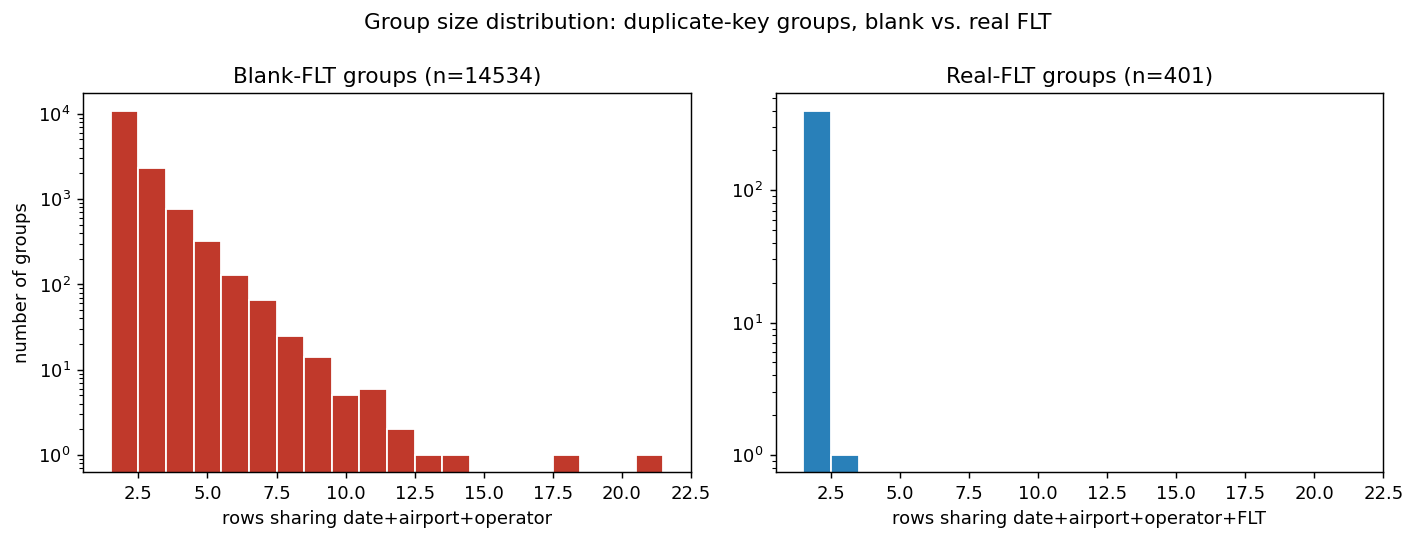

In [11]:
g_dup = dup_keep_na.reset_index(name='n')
is_flt_nan = g_dup['FLT'].isna()

print('Split of the 14,935 duplicate-key groups by whether FLT is blank or a real value:')
print('  blank FLT :', is_flt_nan.sum(), 'groups ->', g_dup.loc[is_flt_nan, 'n'].sum(), 'rows')
print('  real FLT  :', (~is_flt_nan).sum(), 'groups ->', g_dup.loc[~is_flt_nan, 'n'].sum(), 'rows')
print()
print('Group size distribution, blank-FLT groups:')
print(g_dup.loc[is_flt_nan, 'n'].value_counts().sort_index())
print()
print('Group size distribution, real-FLT groups:')
print(g_dup.loc[~is_flt_nan, 'n'].value_counts().sort_index())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
bins = range(2, 23)
axes[0].hist(g_dup.loc[is_flt_nan, 'n'], bins=bins, color='#c0392b', edgecolor='white', align='left')
axes[0].set_title(f'Blank-FLT groups (n={is_flt_nan.sum()})')
axes[0].set_xlabel('rows sharing date+airport+operator')
axes[0].set_ylabel('number of groups')
axes[0].set_yscale('log')
axes[1].hist(g_dup.loc[~is_flt_nan, 'n'], bins=bins, color='#2980b9', edgecolor='white', align='left')
axes[1].set_title(f'Real-FLT groups (n={(~is_flt_nan).sum()})')
axes[1].set_xlabel('rows sharing date+airport+operator+FLT')
axes[1].set_yscale('log')
fig.suptitle('Group size distribution: duplicate-key groups, blank vs. real FLT')
fig.tight_layout()


Two very different distributions. Real-FLT groups are almost all size 2 (400 of 401), with a single
size-3 group — small, consistent with the occasional genuine multi-strike or multiply-reported flight.
Blank-FLT groups go all the way up to size 21, which is not plausible as "one flight, 21 wildlife
strikes." **97.8% of the flagged rows (35,094 of 35,897) come from blank-FLT groups** — whatever's
happening here, it's overwhelmingly a blank-`FLT` phenomenon, not a real-`FLT` one. Time to read the
actual rows.

In [12]:
cols = ['INDEX_NR', 'TIME', 'SPECIES', 'REMARKS']

print('=== Largest blank-FLT group: KDTW, 2021-08-17, OPERATOR=UNKNOWN, n=21 ===')
m1 = (df['INCIDENT_DATE'] == '2021-08-17') & (df['AIRPORT_ID'] == 'KDTW') & \
     (df['OPERATOR'] == 'UNKNOWN') & (df['FLT'].isna())
with pd.option_context('display.max_colwidth', 90):
    print(df.loc[m1, cols].to_string(index=False))

print()
print('=== Second-largest blank-FLT group: KDEN, 2022-06-24, OPERATOR=UNKNOWN, n=18 (first 6 rows) ===')
m2 = (df['INCIDENT_DATE'] == '2022-06-24') & (df['AIRPORT_ID'] == 'KDEN') & \
     (df['OPERATOR'] == 'UNKNOWN') & (df['FLT'].isna())
with pd.option_context('display.max_colwidth', 90):
    print(df.loc[m2, cols].head(6).to_string(index=False))


=== Largest blank-FLT group: KDTW, 2021-08-17, OPERATOR=UNKNOWN, n=21 ===
 INDEX_NR  TIME       SPECIES                                                                                                                                                         REMARKS
  1526149 10:35 Big brown bat Remains found during scheduled runway closure.  No damage reported. DAY. Please merge report 2021-09-02-120238  with 2021-08-24-091639. Duplicate report. .DAY.
  1531071 12:30 Big brown bat                                                                                 Remains found during scheduled runway closure.  No damage reported. DAY.  .DAY.
  1531072 12:37      Killdeer                                                                                  Remains found during scheduled runway closure.  No damage reported. DAY. .DAY.
  1531073 12:38      Killdeer                                                                                 Remains found during scheduled runway closure.  No damag

The `REMARKS` text answers the question directly, and it isn't the answer the grouping key alone
would suggest. These are not the same strike logged 21 times, and they are not 21 strikes suffered by one
flight. They're **wildlife remains found during scheduled runway inspections** — genuinely separate
carcasses discovered across a single day's sweeps of the same airfield, each correctly given its own
`INDEX_NR`, with no flight number (or `REG`, or `AC_CLASS`, or `PHASE_OF_FLIGHT`) because there is no
specific flight to attach them to. Several remarks explicitly say *"no strikes reported"* — these are
carcasses found on the ground, not confirmed in-flight collisions. Different species (bats and birds
mixed), spread across several hours (09:44 to 13:37 in the KDTW case) — not one event. The `KDEN` group
shows the same pattern (mostly `Horned lark`, a grassland species common around airfields, plus one
`Gopher snake` — which by itself rules out "aircraft collision" as the shared story for every row here).

This means: the majority of the raw "duplication" signal is **real, distinct data** — not the same report
double-logged, and not genuine multi-strike flights either. It's a side effect of grouping on a key
(`FLT`) that these particular reports were never going to have.

In [13]:
print('=== A real-FLT duplicate group for comparison: KAMA, 2016-08-25, Southwest 5559 ===')
m3 = (df['INCIDENT_DATE'] == '2016-08-25') & (df['AIRPORT_ID'] == 'KAMA') & \
     (df['OPERATOR'] == 'SOUTHWEST AIRLINES') & (df['FLT'] == '5559')
with pd.option_context('display.max_colwidth', 90):
    print(df.loc[m3, ['INDEX_NR', 'TIME', 'PHASE_OF_FLIGHT', 'DAMAGE_LEVEL', 'REMARKS']].to_string(index=False))

print()
print('=== Another real-FLT pair: KCLT, 2018-06-21, American 600 ===')
m4 = (df['INCIDENT_DATE'] == '2018-06-21') & (df['AIRPORT_ID'] == 'KCLT') & \
     (df['OPERATOR'] == 'AMERICAN AIRLINES') & (df['FLT'] == '600')
for idx, row in df.loc[m4].iterrows():
    print(f"--- INDEX_NR {row['INDEX_NR']}, TIME {row['TIME']} ---")
    print(row['REMARKS'])
    print()


=== A real-FLT duplicate group for comparison: KAMA, 2016-08-25, Southwest 5559 ===
 INDEX_NR  TIME PHASE_OF_FLIGHT DAMAGE_LEVEL                                                                              REMARKS
   783426 17:43        Approach            N                                                           Bird struck the F/O window
   783523 17:43        Approach          NaN                                                                                  NaN
   784127 17:43        Approach            N FINAL RWY4 50 FEET AGL, TYPE OF BIRD AND POSITION THE BIRD HIT THE AIRCRAFT UNKNOWN.

=== Another real-FLT pair: KCLT, 2018-06-21, American 600 ===
--- INDEX_NR 819871, TIME 05:55 ---
MOR Remarks: AAL600 HAD A BIRD STRIKE ON THE NOSE CONE AS THEY WERE DECELERATING AFTER LANDING RUNWAY 18L. PILOT REPPORTED A MARK ON THE NOSE CONE BELOW THE FIRST OFFICERS WINDOW. HE ADVISED THAT MAINTENACE WAS GOING TO TAKE A LOOK AT IT. Other Remarks: One small bird carcass was found and retrie

This is a different (and smaller) phenomenon. The `KAMA`/Southwest example is 3 rows at the exact
same time (17:43) and phase (`Approach`), with overlapping descriptions of what reads like one physical
strike event. The `KCLT`/American 600 pair is more clearly two *sequential* reports about the same
underlying strike as an investigation progressed — one is the initial MOR-sourced report describing the
pilot's account and airport ops finding a carcass; the other is a follow-up (same flight, same date, same
`05:55` time) noting the Smithsonian's tissue-sample result. Both rows keep a distinct `INDEX_NR`.

The `SOURCE` field has an explicit `"Multiple"` value for exactly this situation (41,137 rows use it) —
so FAA's process does have a mechanism for consolidating multi-source reports about one event into a
single row. The `KCLT` example shows that consolidation isn't complete: the same physical event can still
end up as two separate rows when reports come in as fully separate submissions rather than being merged
by database staff. **This means even the small real-`FLT` bucket isn't a clean count of "distinct
strikes" — it likely contains some amount of the same event reported more than once**, on top of (rather
than instead of) genuine multi-strike flights. Untangling that fully would mean text-comparing `REMARKS`
across same-day/same-flight rows, which is out of scope for this pass but worth flagging for later.

In [14]:
key_noflt = ['INCIDENT_DATE', 'AIRPORT_ID', 'OPERATOR']
g2 = df.groupby(key_noflt, dropna=False).size()
dup2 = g2[g2 > 1]
print('Grouping WITHOUT FLT: (date, airport, operator) only')
print('  groups with size>1:', len(dup2), '| rows in those groups:', dup2.sum(),
      f'({dup2.sum()/len(df)*100:.2f}% of dataset)')
print()
print('Largest groups:')
print(dup2.sort_values(ascending=False).head(6))


Grouping WITHOUT FLT: (date, airport, operator) only
  groups with size>1: 28441 | rows in those groups: 69863 (19.73% of dataset)

Largest groups:
INCIDENT_DATE  AIRPORT_ID  OPERATOR          
2021-08-17     KDTW        UNKNOWN               21
2022-06-24     KDEN        UNKNOWN               18
2025-09-26     ZZZZ        SOUTHWEST AIRLINES    16
2025-10-09     ZZZZ        SOUTHWEST AIRLINES    16
2006-09-14     KSDF        UPS AIRLINES          15
2000-05-15     KPHX        UNKNOWN               14
dtype: int64


In [15]:
print('=== One of the new large groups that appears only once FLT is dropped: ZZZZ, 2025-09-26, Southwest ===')
m5 = (df['INCIDENT_DATE'] == '2025-09-26') & (df['AIRPORT_ID'] == 'ZZZZ') & (df['OPERATOR'] == 'SOUTHWEST AIRLINES')
with pd.option_context('display.max_colwidth', 70):
    print(df.loc[m5, ['INDEX_NR', 'FLT', 'REG', 'SPECIES']].head(10).to_string(index=False))


=== One of the new large groups that appears only once FLT is dropped: ZZZZ, 2025-09-26, Southwest ===
 INDEX_NR  FLT    REG              SPECIES
  1801771 2684 N8325D     American kestrel
  1801772 2002 N8868L         Gray catbird
  1804727 1725 N917WN Unknown bird - small
  1809561  NaN N8753Q         Unknown bird
  1809562 4521 N7748A         Unknown bird
  1809614 3313 N485WN         Unknown bird
  1809616 1246 N473WN         Unknown bird
  1809619  NaN N8884Q         Unknown bird
  1809814 2612 N8523W         Unknown bird
  1810369 1323 N239WN         Unknown bird


Dropping `FLT` from the key roughly **doubles** the flagged rows (19.73% vs. 10.14%) — but it isn't
a clean substitute, because it trades exposure to one non-identifying bucket (blank `FLT`) for exposure
to another: `AIRPORT_ID == "ZZZZ"` (the placeholder code for the same `"UNKNOWN"` airport bucket confirmed
earlier). The `ZZZZ`/Southwest/2025-09-26 group above has 16 rows, but each one has a *different* real
`FLT` and a *different* `REG` (tail number) — these are 16 genuinely distinct strikes across Southwest's
whole fleet on one calendar day, each discovered on a different aircraft after the fact (so the specific
airport where the strike actually happened couldn't be pinned down), not 16 strikes on one flight.
Removing `FLT` from the grouping key doesn't remove this kind of artifact, it just relocates it.

**Grain audit conclusion.** The evidence doesn't support a single tidy answer, but it does support a
confident, specific one:

- `INDEX_NR` is safe to treat as one-row-per-*report* (99.998% unique, and the 8 exceptions are a fully
  understood, narrow pattern).
- The large apparent "duplication" under `(date, airport, operator, FLT)` is overwhelmingly (97.8%) a
  side effect of grouping blank `FLT` values together, not real duplicate reports or genuine multi-strike
  flights. The underlying rows are legitimately separate strike reports.
- A small residual (401 groups, 803 rows, 0.23% of the dataset) shares a real, matching flight number, and
  spot-checking shows this bucket likely contains some genuine same-event re-reporting alongside genuine
  multi-strike flights — not separable without deeper text work on `REMARKS`.
- **For "how many strike reports exist," `INDEX_NR` ~ row count is fine.** For "how many physical strikes
  occurred," there's a small, currently unquantified amount of likely double-counting concentrated in that
  801-row real-`FLT` bucket — worth a dedicated pass later, not urgent now.

## 5. Missingness over time

Six fields, tracked by `INCIDENT_YEAR`: the four named in the diagnosis (`TIME`, `PHASE_OF_FLIGHT`,
`HEIGHT`, `SPEED`), plus `FLT` (to connect this back to the grain audit above) and `DAMAGE_LEVEL` (central
to any future safety analysis, and not previously checked over time).

               n_rows  TIME  PHASE_OF_FLIGHT  HEIGHT  SPEED   FLT  DAMAGE_LEVEL
INCIDENT_YEAR                                                                  
1990             2120  13.5             80.7    76.3   59.0   2.8          80.3
1991             2515   5.2             86.8    79.5   62.2   7.4          85.8
1992             2652   4.7             85.8    78.4   58.7   5.6          83.6
1993             2625   5.4             85.2    77.1   57.0   5.9          80.8
1994             2707   6.5             86.1    77.9   56.3   7.0          85.0
1995             2827   5.1             85.3    77.0   55.6   7.0          86.4
1996             3031   6.8             81.9    72.3   50.3   8.5          79.8
1997             3560   7.7             79.7    68.8   48.8   3.4          80.6
1998             3808  30.9             76.9    68.0   47.2   3.0          75.6
1999             5118  28.8             67.8    57.2   36.6   2.7          83.3
2000             6028  29.8             

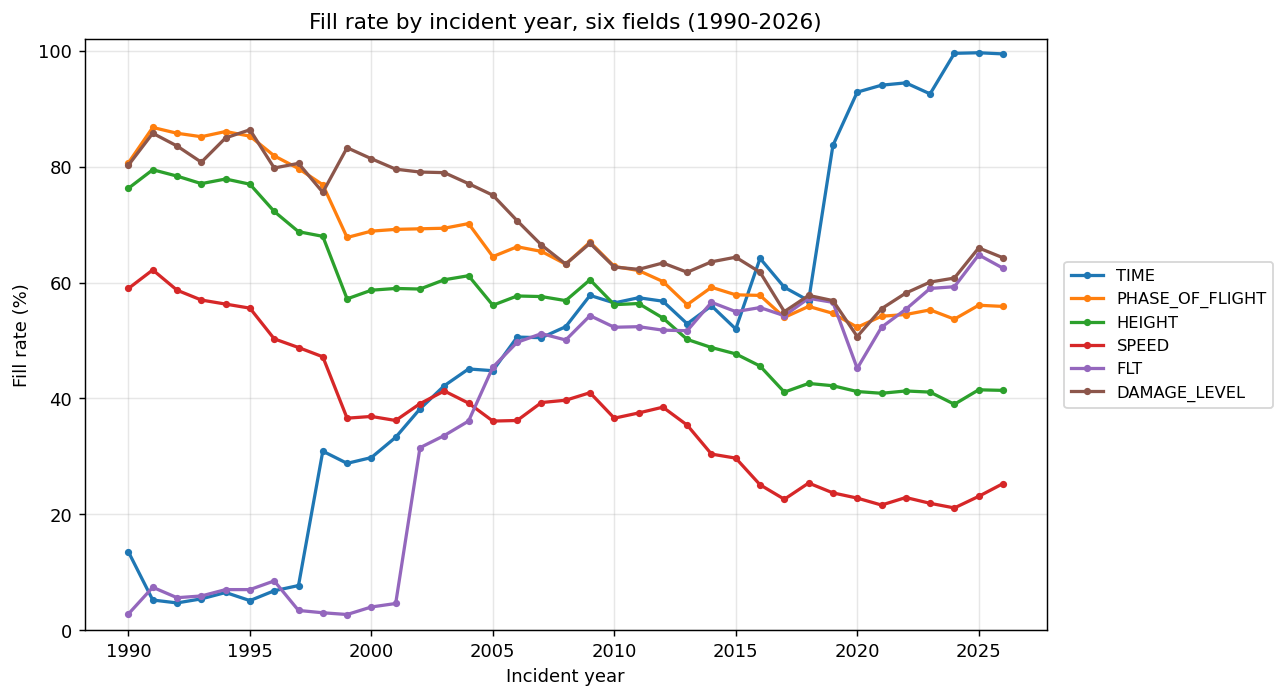

In [16]:
fields = ['TIME', 'PHASE_OF_FLIGHT', 'HEIGHT', 'SPEED', 'FLT', 'DAMAGE_LEVEL']
fill = df.groupby('INCIDENT_YEAR')[fields].apply(lambda g: g.notna().mean() * 100).round(1)
counts = df.groupby('INCIDENT_YEAR').size().rename('n_rows')
by_year = pd.concat([counts, fill], axis=1)
print(by_year.to_string())

fig, ax = plt.subplots(figsize=(10, 5.5))
for f in fields:
    ax.plot(by_year.index, by_year[f], marker='o', markersize=3, linewidth=1.8, label=f)
ax.set_xlabel('Incident year')
ax.set_ylabel('Fill rate (%)')
ax.set_title('Fill rate by incident year, six fields (1990-2026)')
ax.set_ylim(0, 102)
ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()


The 1990 and 2025 fill rates match the diagnosis almost exactly (`TIME`: 13.5% -> 99.7%;
`PHASE_OF_FLIGHT`: 80.7% -> 56.1%; `HEIGHT`: 76.3% -> 41.5%; `SPEED`: 59.0% -> 23.1%), and the 1990/2020/
2025 row counts (2,120 / 11,627 / 24,459) match too — good confirmation the original profiling was done
correctly, not just approximately right.

New from tracking `FLT` and `DAMAGE_LEVEL` over time:

- **`FLT` was barely collected at all before 2002** — under 9% filled every year from 1990-2001, then
  jumps to 31.5% in 2002 and climbs steadily to 64.8% by 2025. This matters directly for the grain audit:
  it means the blank-`FLT` grouping artifact should, in principle, be *worse* in the pre-2002 data. It
  isn't concentrated there, though — the year-by-year count of rows caught in blank-`FLT` duplicate groups
  (checked separately, not shown here) tracks the dataset's overall growth rather than clustering in the
  low-`FLT`-coverage era. That's consistent with the carcass-found-during-inspection story: those reports
  will have a blank `FLT` in any era, because there genuinely isn't a flight to record, not because the
  form didn't ask.
- **`DAMAGE_LEVEL` completeness declined too** — from ~80-86% in the mid-1990s down to ~55-67% through
  the 2010s-2020s, a similar shape to `PHASE_OF_FLIGHT`/`HEIGHT`/`SPEED`. Any future analysis of damage
  rates over time needs the same caution already flagged for those three fields.
- **2026 should be read as provisional, not just partial.** It's not only that the calendar year isn't
  over — wildlife strike reports appear to take weeks/months to be entered after the incident (visible
  earlier in a `LUPDATE`-vs-`INCIDENT_DATE` gap on recent rows), so the last few months of any partial year
  are likely undercounted on top of the calendar effect.

**Bottom line for later phases:** `TIME` is trustworthy for recent years and untrustworthy before ~1998;
`PHASE_OF_FLIGHT`, `HEIGHT`, `SPEED`, and `DAMAGE_LEVEL` all became *less* complete over time, which means
a naive "how has strike severity/altitude/speed changed since 1990" analysis would mostly be measuring
what got recorded, not what happened, unless it explicitly accounts for this.

## 6. Outlier pass: `SPEED`, `HEIGHT`, `COST_REPAIRS`

Finding and documenting only — nothing is fixed in this notebook.

### `SPEED`

In [17]:
print(df['SPEED'].describe())
print()
print('Rows with SPEED > 300 knots:', (df['SPEED'] > 300).sum())
print()
print('Top 10 SPEED values:')
print(df['SPEED'].dropna().sort_values(ascending=False).head(10))


count    109120.000000
mean        143.111483
std          47.139307
min           0.000000
25%         120.000000
50%         140.000000
75%         160.000000
max        2700.000000
Name: SPEED, dtype: float64

Rows with SPEED > 300 knots: 143

Top 10 SPEED values:
349331    2700.0
262730     541.0
204076     400.0
350590     400.0
346462     400.0
300083     400.0
337982     400.0
350395     381.0
350183     381.0
85171      380.0
Name: SPEED, dtype: float64


In [18]:
top_speed = df['SPEED'].idxmax()
print(f'=== The single highest SPEED value in the dataset: {df.loc[top_speed, "SPEED"]} knots ===')
row = df.loc[top_speed]
print(f"INDEX_NR {row['INDEX_NR']}, {row['INCIDENT_DATE']}, {row['OPERATOR']}, {row['AIRCRAFT']}, "
      f"phase={row['PHASE_OF_FLIGHT']}, HEIGHT={row['HEIGHT']}, DAMAGE_LEVEL={row['DAMAGE_LEVEL']}")
print()
print('REMARKS:')
print(row['REMARKS'])


=== The single highest SPEED value in the dataset: 2700.0 knots ===
INDEX_NR 1867606, 2026-05-18, JETBLUE AIRWAYS, A-320, phase=Climb, HEIGHT=10000.0, DAMAGE_LEVEL=N

REMARKS:
On May 18, 2026, I was serving as Captain on Flight 225 from JFK to TPA. During climb out from JFK, passing approximately 9,000 11,000 feet, the aircraft experienced a bird strike.  The bird impacted just below the Captain’s windshield, and debris from the strike traveled upward across the Captain’s window. Immediately following the strike, we requested a level-off and vectors from ATC to allow time to assess potential damage to the Captain’s windshield and evaluate for any other aircraft abnormalities.  Initial indications showed no visible structural damage and no abnormal aircraft indications. However, due to the System Operations Center operating out of the backup location in Woodbury, we initiated a SATCOM call to Maintenance Control (MCC) for further guidance. For approximately 10 minutes, we were unable to

**2,700 knots is roughly 4x the speed of sound — no aircraft in this dataset, or in civil aviation,
does that.** But this is one of the cleaner outlier catches you'll find in real data, because the
`REMARKS` field is a first-person account from the flight's captain, and it directly contradicts the
recorded number: *"we elected to cruise at FL280 and 280 knots"* — 280 knots, almost certainly transcribed
with an extra digit into `2700`. `HEIGHT` for this same row (10,000 ft) matches the remarks' own
"passing approximately 9,000 to 11,000 feet" almost exactly, so only `SPEED` is wrong here, not `HEIGHT` —
useful to know if this ever gets corrected rather than dropped.

In [19]:
second = df['SPEED'].sort_values(ascending=False).index[1]
row2 = df.loc[second]
print(f"=== Second-highest SPEED: {row2['SPEED']} knots, INDEX_NR {row2['INDEX_NR']} ===")
print(f"{row2['INCIDENT_DATE']}, {row2['OPERATOR']}, {row2['AIRCRAFT']}, phase={row2['PHASE_OF_FLIGHT']}, "
      f"HEIGHT={row2['HEIGHT']}")
print(row2['REMARKS'])
print()
print('For context, the rest of the SPEED>300 tail (excluding the two rows above) looks physically')
print('ordinary for jet aircraft climbing/descending through the mid-teens in altitude:')
print(df.loc[(df['SPEED'] > 300) & (df['SPEED'] < 541), ['SPEED', 'HEIGHT', 'PHASE_OF_FLIGHT']]
      .sort_values('SPEED', ascending=False).head(8).to_string(index=False))


=== Second-highest SPEED: 541.0 knots, INDEX_NR 1476144 ===
2023-09-14, UNITED AIRLINES, B-737-900, phase=Descent, HEIGHT=32000.0
Snarge on nose and windshield. 737-924ER, Engine Manufacturer CFM INTL Classification Standard Engine Model CFM56-7B26E Smithsonian Wildlife/Species Identification: Wilson s warbler (Cardellina pusilla)

For context, the rest of the SPEED>300 tail (excluding the two rows above) looks physically
ordinary for jet aircraft climbing/descending through the mid-teens in altitude:
 SPEED  HEIGHT PHASE_OF_FLIGHT
 400.0 18000.0         Descent
 400.0 11000.0         Descent
 400.0 25000.0         Descent
 400.0  1000.0        Approach
 400.0 21000.0           Climb
 381.0 13350.0         Descent
 381.0 13350.0         Descent
 380.0 16000.0         Descent


541 knots indicated airspeed at FL320 in a 737-900 is also implausible — the FAA field dictionary
confirms `SPEED` is specifically **indicated** airspeed, and no 737 variant's structural limit (`Vmo`)
comes anywhere close to 541 KIAS — but there's no equivalent smoking-gun text for this one the way there
is for the 2,700-knot row, so it's flagged with lower confidence.

The rest of the >300-knot tail (143 rows total, minus these two) is a different story: values cluster in
the 300-400 knot range at climb/descent through 10,000-25,000 ft, which is genuinely plausible for a jet
transitioning through that altitude band. **Plausibility bound used here: `SPEED > 500` knots is not
achievable by any aircraft type in this dataset** (a deliberately generous ceiling — even 400 knots is
already at or above most narrow-body jets' `Vmo`). That bound flags exactly the two rows above and nothing
else; the 400-knot cluster (5 rows) is noted as worth a second look but not treated as a confirmed error.

### `HEIGHT`

In [20]:
print(df['HEIGHT'].describe())
print()
print('Negative HEIGHT values:', (df['HEIGHT'] < 0).sum())
print()
print('HEIGHT == 0, crossed with PHASE_OF_FLIGHT (sanity check -- should be ground ops only):')
print(df.loc[df['HEIGHT'] == 0, 'PHASE_OF_FLIGHT'].value_counts(dropna=False))
print()
print('HEIGHT > 20,000 ft, crossed with PHASE_OF_FLIGHT (sanity check -- should be climb/descent/en route):')
print(df.loc[df['HEIGHT'] > 20000, 'PHASE_OF_FLIGHT'].value_counts(dropna=False))


count    175448.000000
mean        882.413450
std        1856.467496
min           0.000000
25%           0.000000
50%          50.000000
75%        1000.000000
max       32000.000000
Name: HEIGHT, dtype: float64

Negative HEIGHT values: 0

HEIGHT == 0, crossed with PHASE_OF_FLIGHT (sanity check -- should be ground ops only):
PHASE_OF_FLIGHT
Landing Roll    38974
Take-off Run    35503
Taxi              834
Parked            116
Local              95
NaN                38
Name: count, dtype: int64

HEIGHT > 20,000 ft, crossed with PHASE_OF_FLIGHT (sanity check -- should be climb/descent/en route):
PHASE_OF_FLIGHT
En Route    16
Climb        9
Descent      8
Name: count, dtype: int64


`HEIGHT` is confirmed as feet **above ground level** by the FAA field dictionary. Both consistency
checks come back clean: every `HEIGHT == 0` row is a ground-ops phase (landing roll, take-off run, taxi,
parked), and every `HEIGHT > 20,000 ft` row is climb, descent, or en route — no ground-phase row shows up
at altitude, and no air-phase row is stuck at zero. No negative values anywhere.

For a plausibility bound: the highest confirmed bird strike in aviation history is generally cited around
37,000 ft, and commercial aircraft service ceilings top out in the low-to-mid 40,000s. This dataset's
actual maximum is 32,000 ft — comfortably under either threshold. **No `HEIGHT` value in this dataset
fails a reasonable physical plausibility check.** That's a real finding worth stating plainly rather than
manufacturing an outlier that isn't there: unlike `SPEED` (a free-typed number with no natural sanity
check at data-entry time) and `COST_REPAIRS` (below), `HEIGHT`'s failure mode of "an extra digit" would
produce a six-figure altitude that's obviously wrong on sight, which may be exactly why none survived into
the published data.

### `COST_REPAIRS`

In [21]:
print(df['COST_REPAIRS'].describe())
print()
print('Lowest values:', sorted(df['COST_REPAIRS'].dropna().unique())[:6])
print()
top10 = df.dropna(subset=['COST_REPAIRS']).sort_values('COST_REPAIRS', ascending=False).head(10)
print('Top 10 COST_REPAIRS rows:')
print(top10[['INDEX_NR', 'INCIDENT_DATE', 'OPERATOR', 'AIRCRAFT', 'DAMAGE_LEVEL', 'COST_REPAIRS']]
      .to_string(index=False))
print()
print('DAMAGE_LEVEL breakdown of the top 30 costliest repairs:')
print(top10.index)  # placeholder to keep top10 referenced; real breakdown below
top30 = df.dropna(subset=['COST_REPAIRS']).sort_values('COST_REPAIRS', ascending=False).head(30)
print(top30['DAMAGE_LEVEL'].value_counts(dropna=False))
print()
print('Median / mean / max repair cost by DAMAGE_LEVEL (checking the coding is internally consistent):')
print(df.groupby('DAMAGE_LEVEL')['COST_REPAIRS'].agg(['median', 'mean', 'max', 'count']).round(0))


count    5.443000e+03
mean     1.481589e+05
std      1.147925e+06
min      2.000000e+00
25%      2.500000e+03
50%      1.200000e+04
75%      5.000000e+04
max      6.000000e+07
Name: COST_REPAIRS, dtype: float64

Lowest values: [np.float64(2.0), np.float64(10.0), np.float64(13.0), np.float64(16.0), np.float64(19.0), np.float64(20.0)]

Top 10 COST_REPAIRS rows:
 INDEX_NR INCIDENT_DATE                       OPERATOR   AIRCRAFT DAMAGE_LEVEL  COST_REPAIRS
  1883789    2026-01-28                ALASKA AIRLINES      A-330            S    60000000.0
  1686950    2009-01-15                     US AIRWAYS      A-320            D    36000000.0
  1437885    2017-10-25 BOEING COMMERCIAL AIRPLANE GRP       C-17            S    15000000.0
  1625318    2023-03-05             SOUTHWEST AIRLINES    B-737-8            S    14500000.0
   700640    2009-02-03                UNITED AIRLINES  B-757-200            S    14000000.0
  1240152    2021-03-08              AMERICAN AIRLINES      A-319            S  

The `DAMAGE_LEVEL` progression (`N` < `M` < `M?` < `S` < `D` by both median and mean repair cost) is
internally consistent — a real positive finding, not just a hunt for problems. But 26 of the top 30
costliest repairs are coded `S` ("Substantial"), not `D` ("Destroyed") — exactly the pattern the original
diagnosis flagged as suspicious. Worth reading the actual rows before concluding it's a miscode.

In [22]:
highest = top10.iloc[0]
print(f"=== Highest COST_REPAIRS in the dataset: ${highest['COST_REPAIRS']:,.0f}, DAMAGE_LEVEL={highest['DAMAGE_LEVEL']} ===")
print(f"INDEX_NR {highest['INDEX_NR']}, {highest['INCIDENT_DATE']}, {highest['OPERATOR']}, {highest['AIRCRAFT']}")
print()
print(df.loc[df['INDEX_NR'] == highest['INDEX_NR'], 'REMARKS'].iloc[0])


=== Highest COST_REPAIRS in the dataset: $60,000,000, DAMAGE_LEVEL=S ===
INDEX_NR 1883789, 2026-01-28, ALASKA AIRLINES, A-330

While on takeoff climb from Runway 27, Alaska 2616 struck multiple canada geese. Aircraft declared an emergency and returned to RWY 36R. Upon inspection, Airport Ops and ARFF located damage to both engines as well as snarge on the leading edges of the wings, flaps and landing gear. On Runway 27, multiple large goose carcasses were located and removed. Bird remains given to CVG s USDA Wildlife Biologist.  SIX PHOTOS Smithsonian Wildlife Identification Comments: 5 bags of samples received. DNA sexing conduced on all samples. Bag 1, carcass #1, DNA sex   Female Bag 2, carcass #2, DNA sex   Female Bag 3, carcass #3, DNA sex   Male Bag 4, engine #1, DNA sex   Male Bag 5, engine #2, DNA sex   Female Carcasses weighed by Joshua Combs, 6.38 lbs, 7.54 lbs, 8.5 lbs. 3.20.26 PER RD: Remarks: Evidence of at least 8 Canada geese was recovered. USDA WS biologist weighed 3 in

**This is the highest-cost row in the dataset, and the original diagnosis pointedly left it
undiscussed** (it only named the *second*-highest, the Miracle-on-the-Hudson row, as an "anchor"). It
turns out to be a very recent, richly documented incident: an Alaska Airlines A330 cargo flight out of
Cincinnati struck multiple Canada geese on initial climb on January 28, 2026, lost an engine, got smoke in
the cockpit, declared an emergency, and returned to land safely — no fatalities, no destroyed airframe.
`DAMAGE_LEVEL = S` here isn't a miscode: the FAA's own damage definitions grade the *airframe*, and this
airframe was repairable (it was towed to the ramp, not written off) even though the engine damage alone
was catastrophically expensive. A \$60M repair bill on a "Substantial"-coded strike makes complete sense
once you know modern high-bypass turbofan engines can cost tens of millions to replace — it isn't evidence
against the coding, it's evidence that engines are expensive.

In [23]:
cost_n = df[(df['DAMAGE_LEVEL'] == 'N') & (df['COST_REPAIRS'].notna())]
print(f'Rows coded DAMAGE_LEVEL=N ("no damage") that still carry a repair cost: {len(cost_n)}')
print()
top_n_cost = cost_n.sort_values('COST_REPAIRS', ascending=False).iloc[0]
print(f"Highest example: ${top_n_cost['COST_REPAIRS']:,.0f}, INDEX_NR {top_n_cost['INDEX_NR']}, {top_n_cost['OPERATOR']}")
print()
print(top_n_cost['REMARKS'][:600] + ' ...')


Rows coded DAMAGE_LEVEL=N ("no damage") that still carry a repair cost: 30

Highest example: $365,000, INDEX_NR 1474919, SWISSAIR

Pilot reported bird strike and aborted take-off. The strike occurred along runway 9C between the intersections with taxiway E2 and runway 4L. Aborting the take-off caused hot brakes and disabled the aircraft temporarily. The emergency on the runway caused ARFF vehicles to come out and cool off brake system and tires. Airport operation removed snarge from the nose/radome of the aircraft and collected bird remains (at least two birds... WS speculates a flock of plover, possibly semipalmated) between runway 4L and taxiway E2 south of centerline. Wildlife services received pictures and bird remain ...


A second, smaller logical check: 30 rows are coded `DAMAGE_LEVEL = N` (no damage) but still carry a
nonzero repair cost, up to \$365,000. Reading the top example resolves it rather than flagging a bug: a
Swissair aircraft aborted takeoff after a bird strike, and *"no damage to the aircraft was caused from the
birds striking the plane. All damage was to the brake system as a result of rapidly aborting take-off."*
`DAMAGE_LEVEL` tracks damage from the wildlife impact specifically; `COST_REPAIRS` tracks total cost
including downstream consequences like an aborted-takeoff brake job. Two fields measuring genuinely
different things, not one field contradicting itself.

**Outlier-pass summary for `COST_REPAIRS`:** no plausibility-bound violations in the way `SPEED` has one —
every value, including the extremes, resolves to a coherent, well-documented real event once read in
context. The main practical note for later phases is the heavy right skew visible in the mean-vs-median
gap for every `DAMAGE_LEVEL` (e.g. `D`: median \$175,000 but mean \$1.79M) — median, not mean, should be
the default summary statistic for repair cost in any future write-up.

## Summary

What this session established, matched against the brief's "expected findings":

- **Is `INDEX_NR` safe to treat as one-row-one-strike?** Yes, for report counting (99.998% unique, 8
  fully-understood exception pairs). Not fully, for physical-strike counting — see the grain-audit
  conclusion above for the small, real caveat.
- **Is the `(date, airport, operator, FLT)` clustering real duplication or an artifact?** Mostly an
  artifact of grouping on blank `FLT` — but the underlying rows are genuine, separate, correctly-recorded
  reports (carcasses found during inspections), not errors. A small residual (0.23% of the dataset) likely
  contains real same-event re-reporting, unresolved and flagged for later.
- **Which fields are safe for a 1990-2025 trend?** `TIME` is unreliable before 1998 (under 9% filled) and
  only genuinely reliable (>90%) from 2019 onward, with a patchy 30-65%-filled middle era in between — not
  a clean "before/after 1998" split (and treat 2026 as provisional beyond the usual partial-year caveat).
  `PHASE_OF_FLIGHT`, `HEIGHT`, `SPEED`, and
  `DAMAGE_LEVEL` all became less complete over the full span — any trend analysis using them needs to
  either restrict to a stable-missingness window or explicitly model the missingness itself.
- **Outlier rows in `SPEED`/`HEIGHT`/`COST_REPAIRS`:** one clear, evidenced error (`SPEED = 2700`, INDEX_NR
  1867606, contradicted by its own remarks), one likely error with weaker evidence (`SPEED = 541`, INDEX_NR
  1476144), and zero in `HEIGHT`. `COST_REPAIRS` extremes all check out as real, documented events rather
  than errors.

**Open items for week 2 and beyond**, noted here rather than chased down now:
- The `OPERATOR == "UNKNOWN"` bucket has at least one sibling (`"UNKNOWN COMMERCIAL"`, 899 rows) — worth a
  fuller sweep for equivalent variants before any operator-level analysis.
- The real-`FLT` duplicate bucket (401 groups) likely mixes genuine multi-strike flights with same-event
  re-reporting; separating the two would need `REMARKS` text comparison.
- `AC_CLASS`'s non-`A`/`B` codes (`C`, `J`, `Y` — 14 rows total) were never pinned down against the FAA's
  Aircraft Type code tab; low priority given how rare they are.